Dataset utilizado: https://universe.roboflow.com/vision-zz6rk/fire_detector-g4lir

In [1]:
!pip install -q ultralytics roboflow
import ultralytics
ultralytics.checks()   # print do resultado = evidência de GPU

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.4/112.6 GB disk)


In [2]:
from roboflow import Roboflow
rf = Roboflow(api_key="MINHA CHAVE")
project = rf.workspace("vision-zz6rk").project("fire_detector-g4lir")
dataset = project.version(1).download("yolov8")   # ajuste o nº da versão
root = dataset.location
print(root)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Fire_detector-1 in yolov8:: 100%|██████████| 9398/9398 [00:02<00:00, 3397.83it/s]


/content/Fire_detector-1


In [3]:
import glob
print(open(f"{root}/data.yaml").read())
for split in ["train", "valid", "test"]:
    imgs = glob.glob(f"{root}/{split}/images/*")
    lbls = glob.glob(f"{root}/{split}/labels/*")
    print(split, "-> imagens:", len(imgs), "| labels:", len(lbls))

names:
- '-'
- fire - v1 2024-01-12 8-02pm
nc: 2
roboflow:
  license: CC BY 4.0
  project: fire_detector-g4lir
  url: https://universe.roboflow.com/vision-zz6rk/fire_detector-g4lir/dataset/1
  version: 1
  workspace: vision-zz6rk
test: ../test/images
train: ../train/images
val: ../valid/images

train -> imagens: 3285 | labels: 3285
valid -> imagens: 938 | labels: 938
test -> imagens: 470 | labels: 470


In [4]:
import yaml
with open(f"{root}/data.yaml") as f:
    cfg = yaml.safe_load(f)

cfg["train"] = f"{root}/train/images"
cfg["val"]   = f"{root}/valid/images"
cfg["test"]  = f"{root}/test/images"
# Opcional, se os nomes das classes estiverem lixo (ajuste conforme o que aparecer):
# cfg["names"] = ["fire"]; cfg["nc"] = 1   # só se houver de fato 1 classe nos labels!

with open(f"{root}/data.yaml", "w") as f:
    yaml.dump(cfg, f)
print(open(f"{root}/data.yaml").read())   # print final = evidência

names:
- '-'
- fire - v1 2024-01-12 8-02pm
nc: 2
roboflow:
  license: CC BY 4.0
  project: fire_detector-g4lir
  url: https://universe.roboflow.com/vision-zz6rk/fire_detector-g4lir/dataset/1
  version: 1
  workspace: vision-zz6rk
test: /content/Fire_detector-1/test/images
train: /content/Fire_detector-1/train/images
val: /content/Fire_detector-1/valid/images



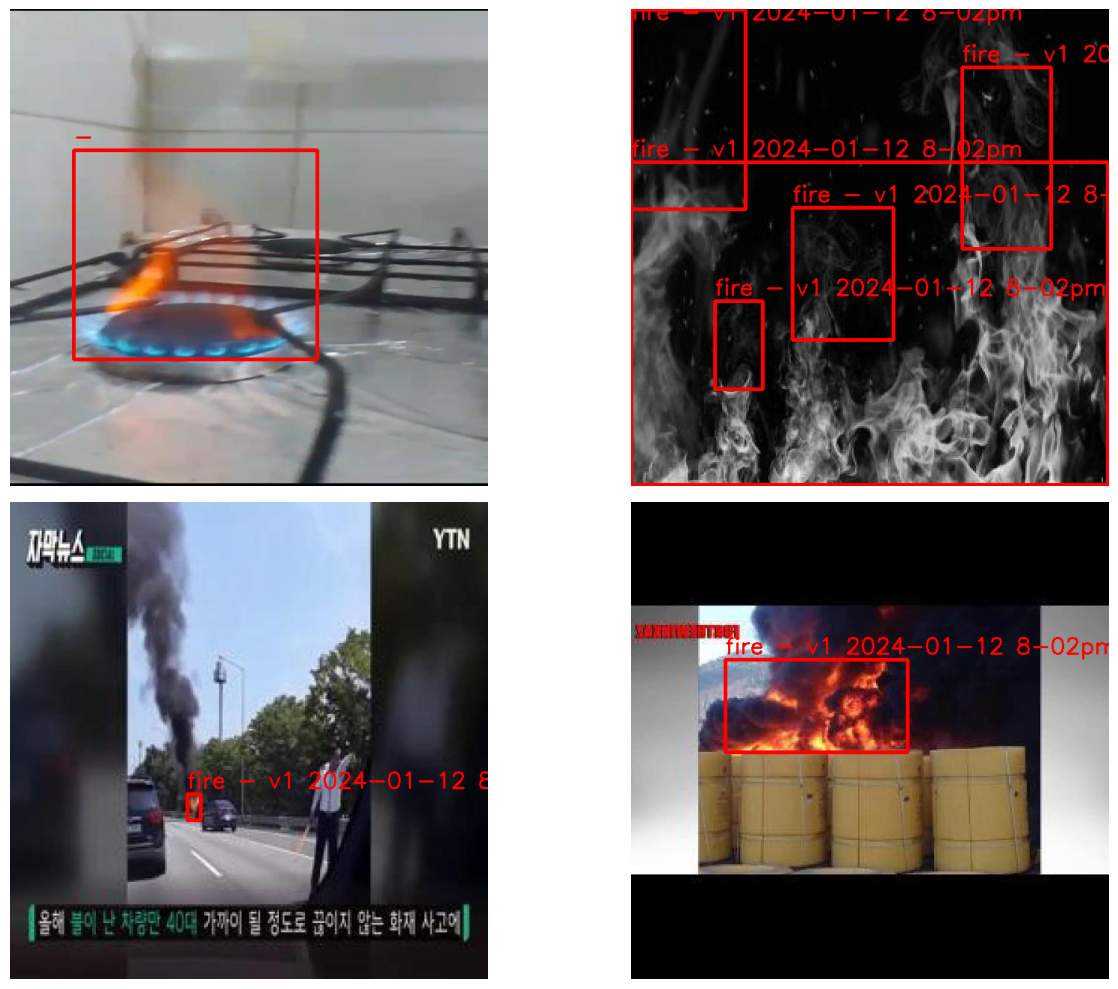

1 0.3875 0.428125 0.38125 0.19375


In [5]:
import cv2, random, matplotlib.pyplot as plt
names = cfg["names"]
files = random.sample(glob.glob(f"{root}/train/images/*"), 4)

plt.figure(figsize=(14, 10))
for i, p in enumerate(files):
    img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    lp = p.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
    for line in open(lp):
        c, xc, yc, bw, bh = line.split()[:5]
        c, xc, yc, bw, bh = int(c), float(xc)*w, float(yc)*h, float(bw)*w, float(bh)*h
        x1, y1, x2, y2 = int(xc-bw/2), int(yc-bh/2), int(xc+bw/2), int(yc+bh/2)
        cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 3)
        cv2.putText(img, str(names[c]), (x1, max(y1-8, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 0, 0), 2)
    plt.subplot(2, 2, i+1); plt.imshow(img); plt.axis("off")
plt.tight_layout(); plt.show()

print(open(lp).read())  # exemplo de label: classe x_centro y_centro largura altura

In [6]:
%%writefile treino.py
# Treinamento YOLOv8n - detecção de fogo (dataset Roboflow Universe: vision-zz6rk/fire_detector-g4lir)
from ultralytics import YOLO

# Carrega pesos pré-treinados (transfer learning)
model = YOLO("yolov8n.pt")

# Treina: 50 épocas, imagens 640x640
results = model.train(
    data="/content/Fire_detector-1/data.yaml",   # ajuste para o seu caminho
    epochs=50,
    imgsz=640,
    batch=16,                      # se faltar memória: 8
    project="/content/runs/detect",
    name="atividade_aula4",
    exist_ok=True,
)

# Avalia no conjunto de validação
metrics = model.val()
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Writing treino.py


In [7]:
!python treino.py

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Fire_detector-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=atividade_aula4, nbs=64, nms=None, opset=None, optimize=

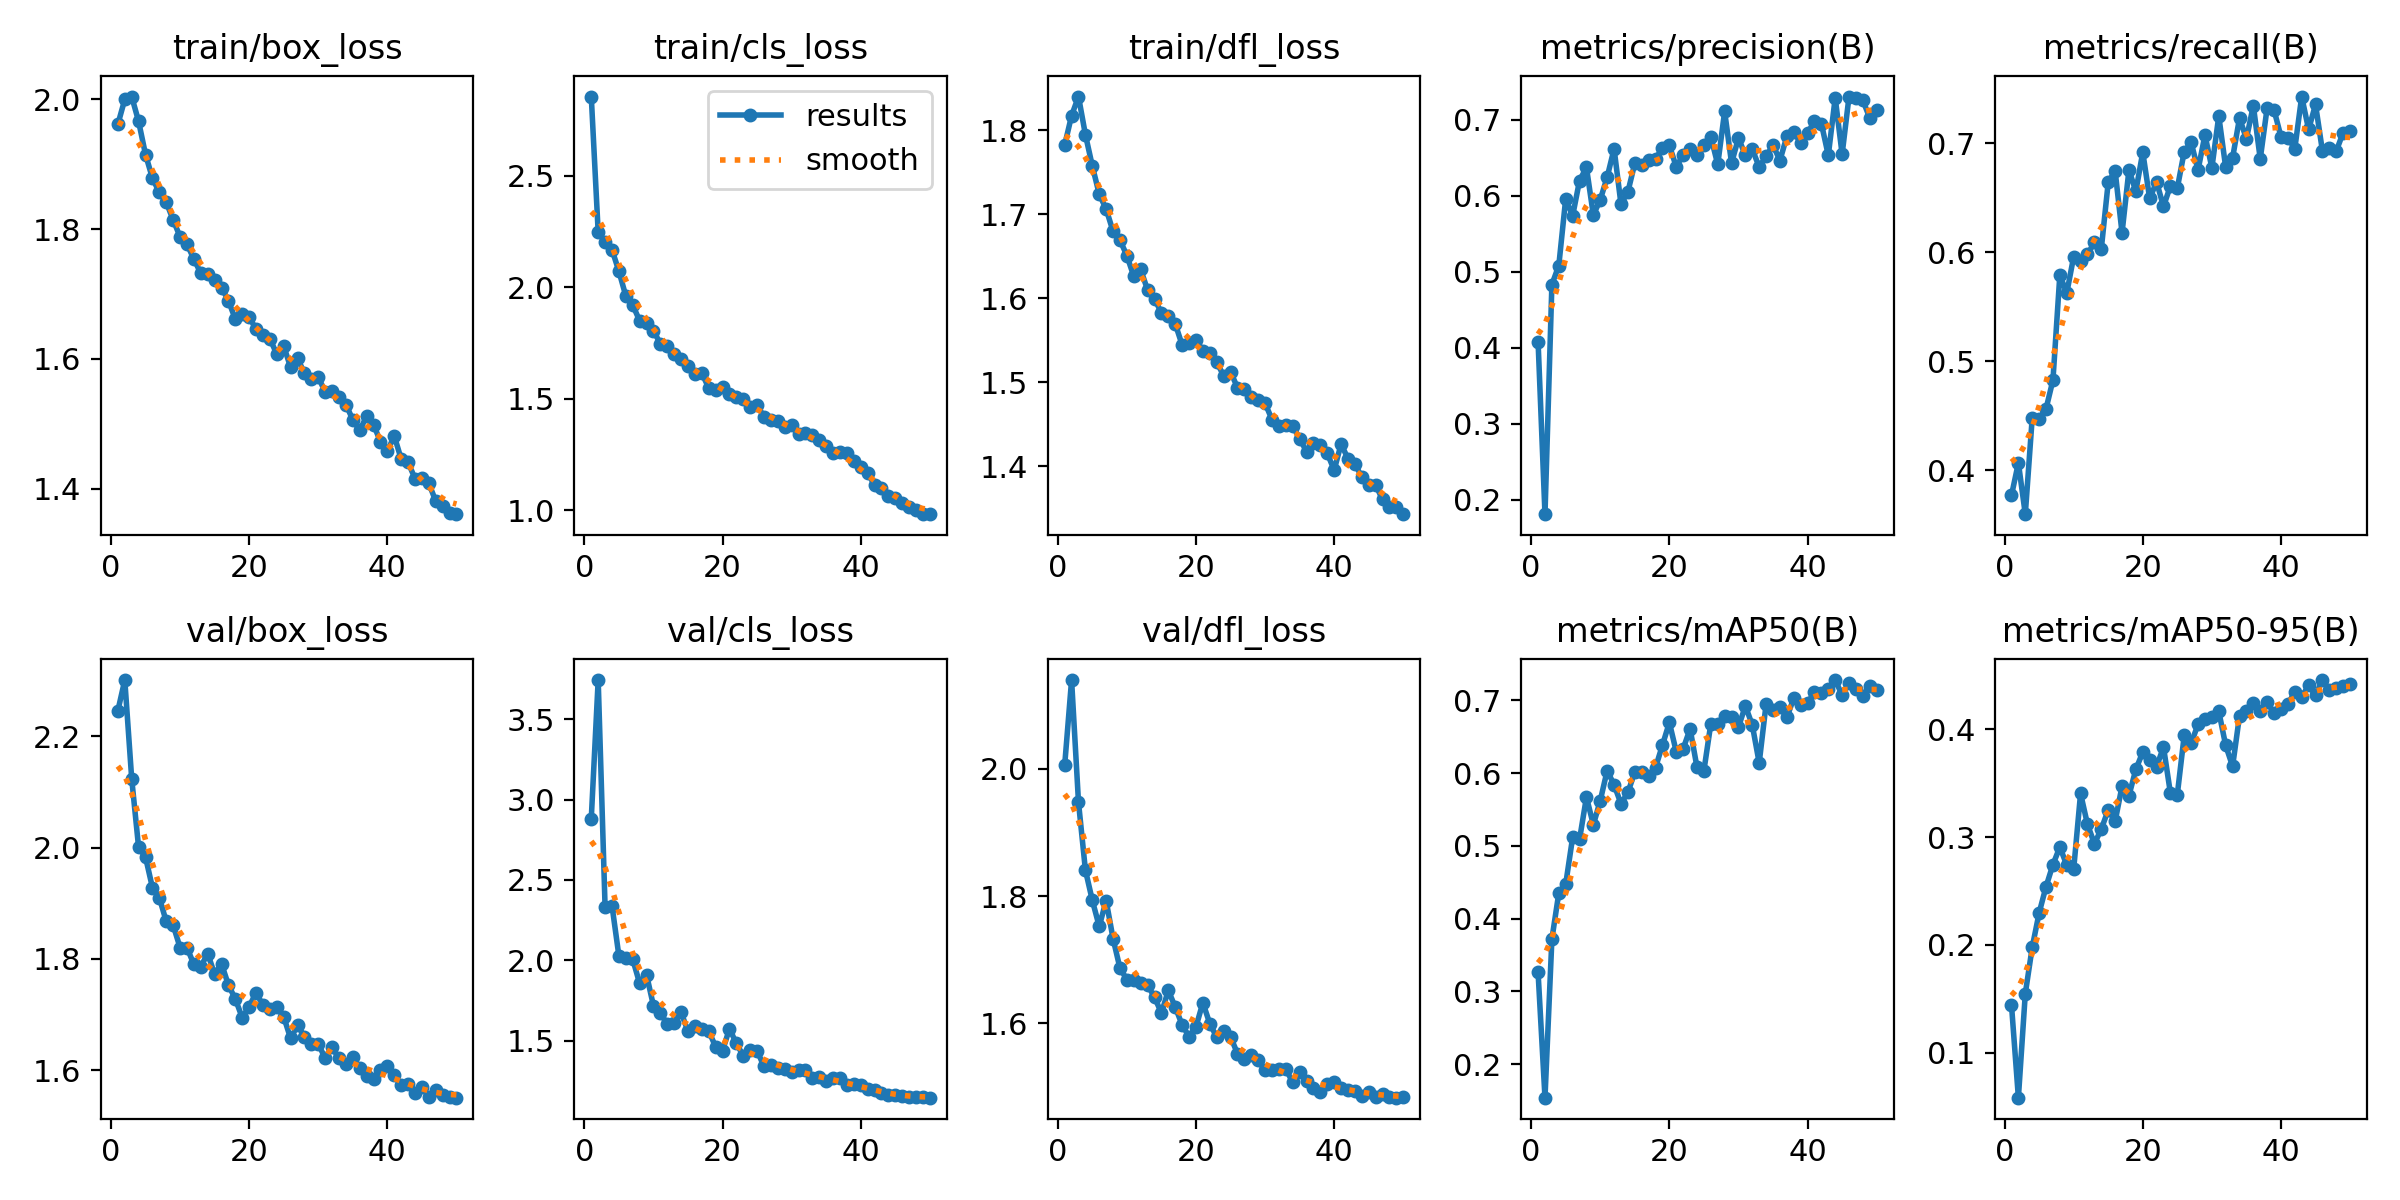

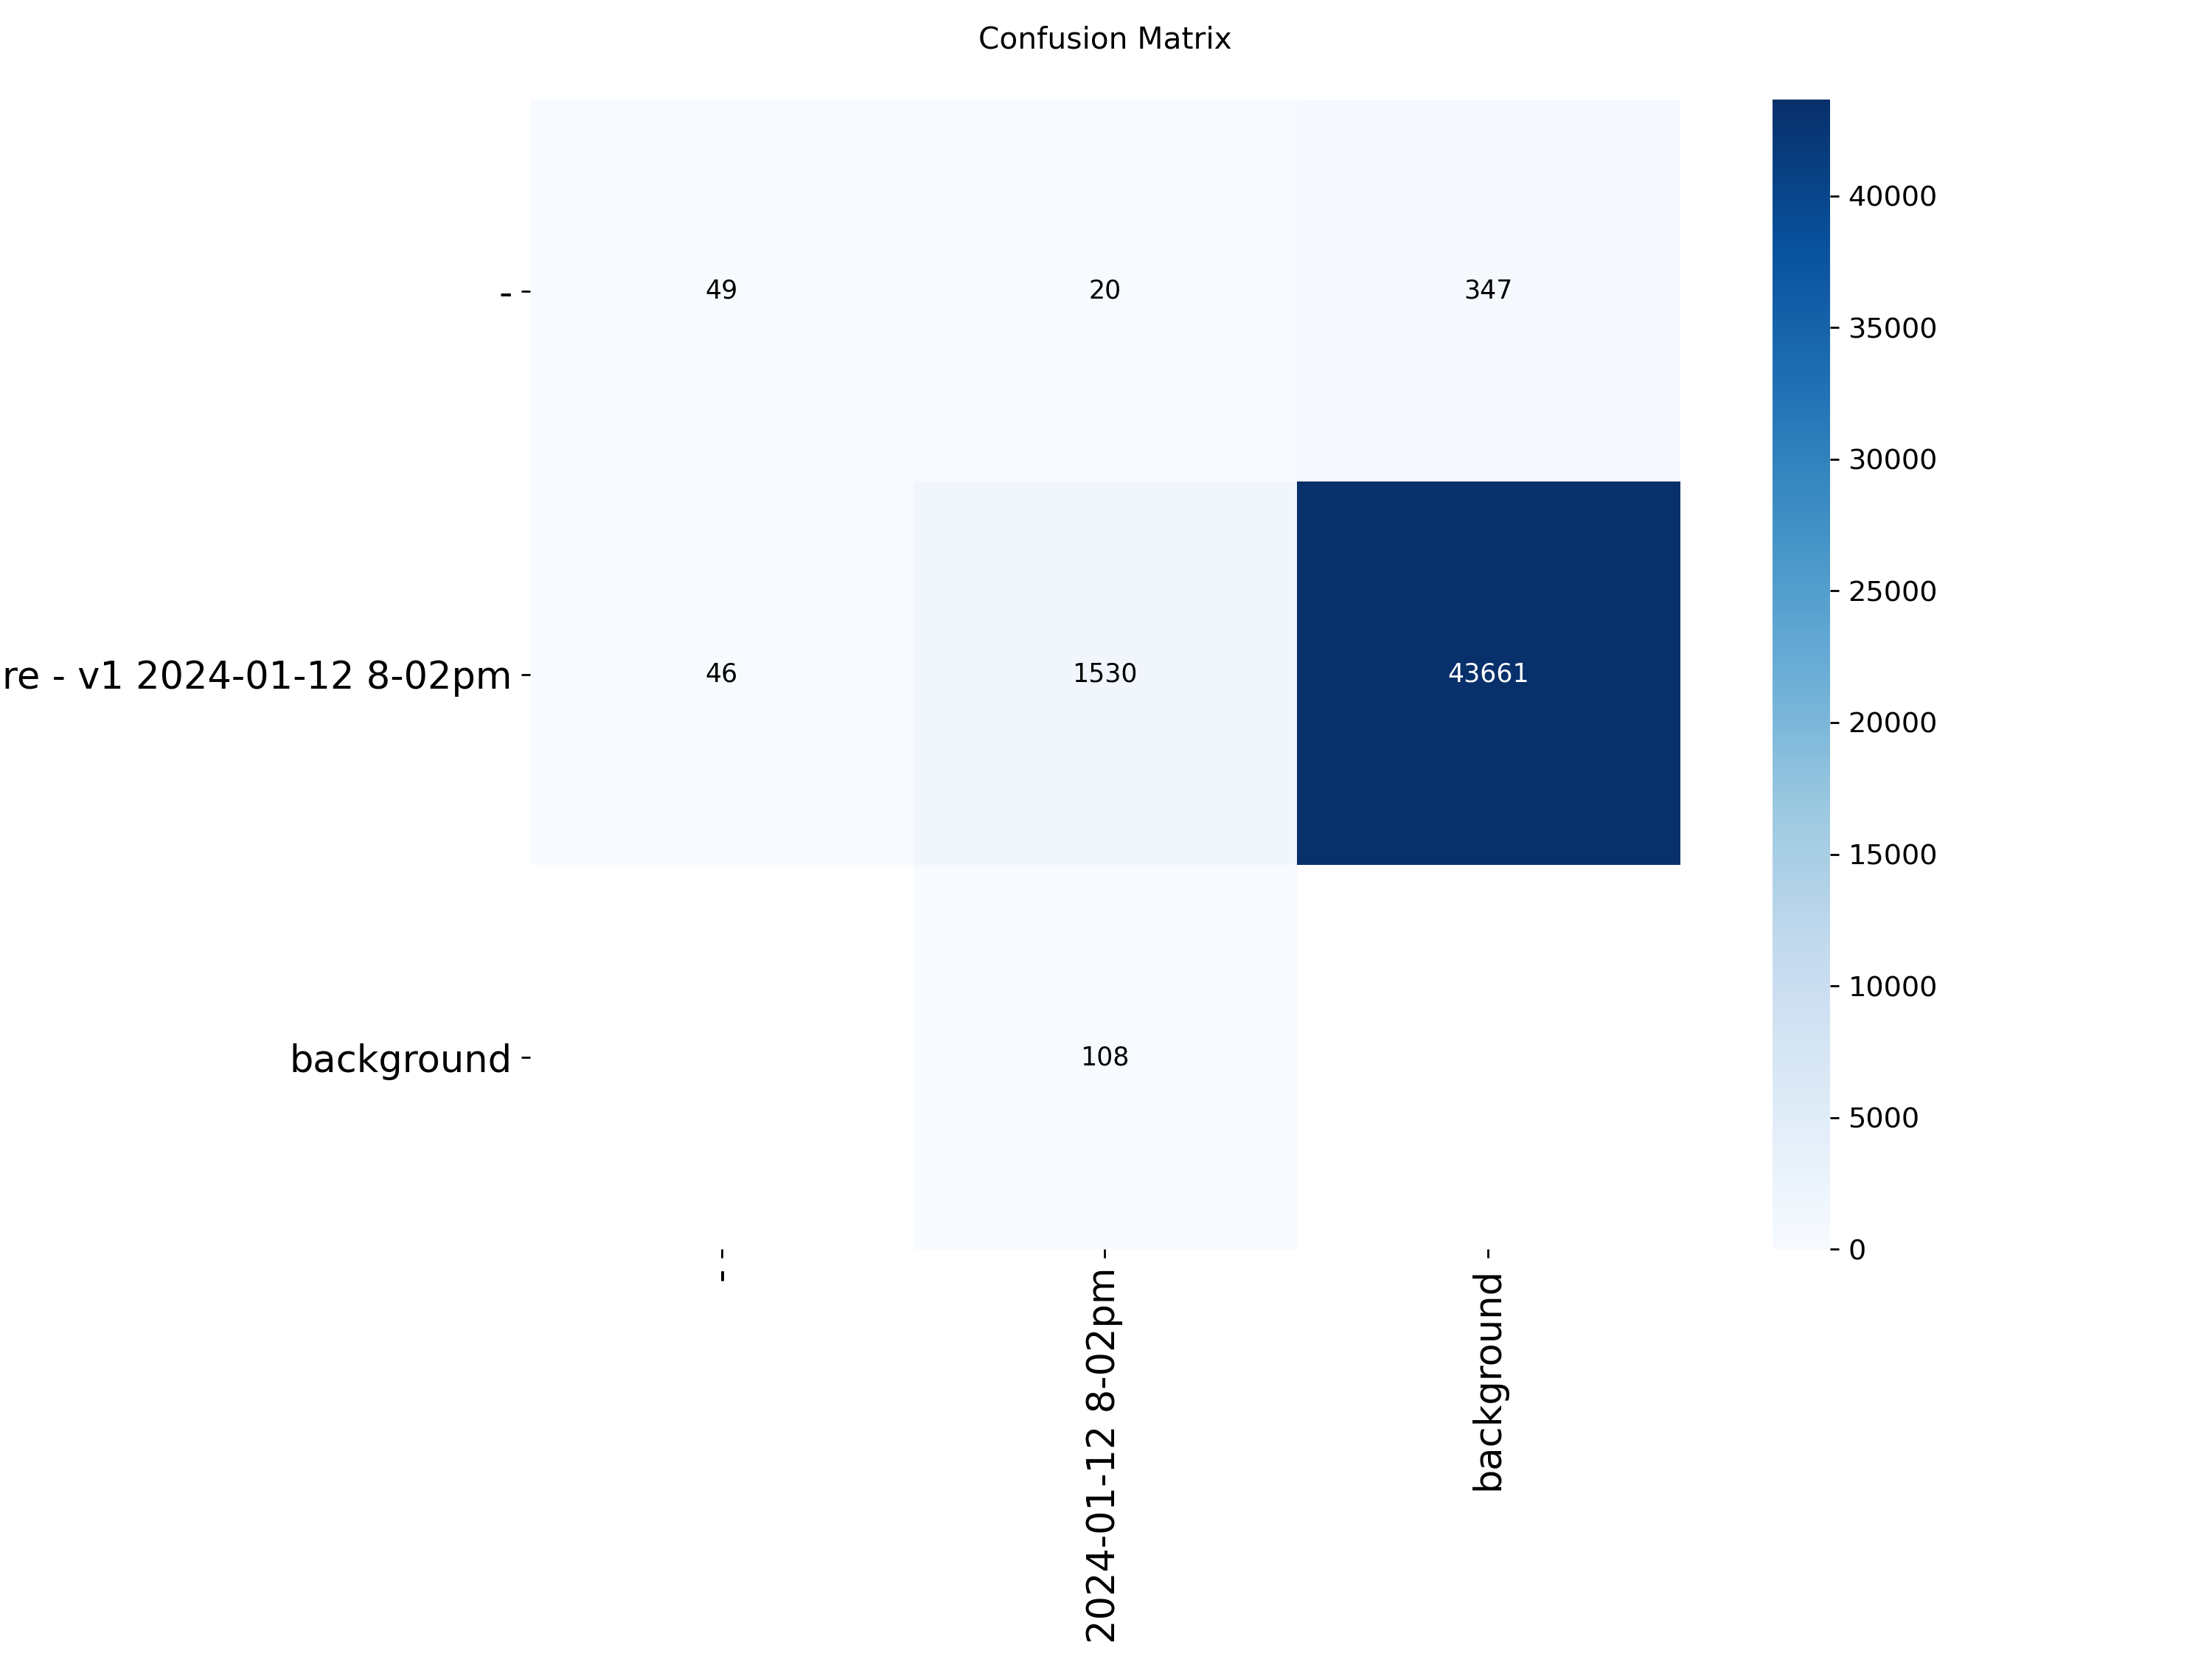

In [8]:
from IPython.display import Image, display
out = "/content/runs/detect/atividade_aula4"
display(Image(f"{out}/results.png"))
display(Image(f"{out}/confusion_matrix.png"))

In [11]:
print(open(f"{root}/data.yaml").read())

names:
- '-'
- fire - v1 2024-01-12 8-02pm
nc: 2
roboflow:
  license: CC BY 4.0
  project: fire_detector-g4lir
  url: https://universe.roboflow.com/vision-zz6rk/fire_detector-g4lir/dataset/1
  version: 1
  workspace: vision-zz6rk
test: /content/Fire_detector-1/test/images
train: /content/Fire_detector-1/train/images
val: /content/Fire_detector-1/valid/images




0: 640x640 1 -, 10.2ms
1: 640x640 3 fire - v1 2024-01-12 8-02pms, 10.2ms
2: 640x640 2 fire - v1 2024-01-12 8-02pms, 10.2ms
3: 640x640 (no detections), 10.2ms
Speed: 17.6ms preprocess, 10.2ms inference, 5.6ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/inferencias/teste


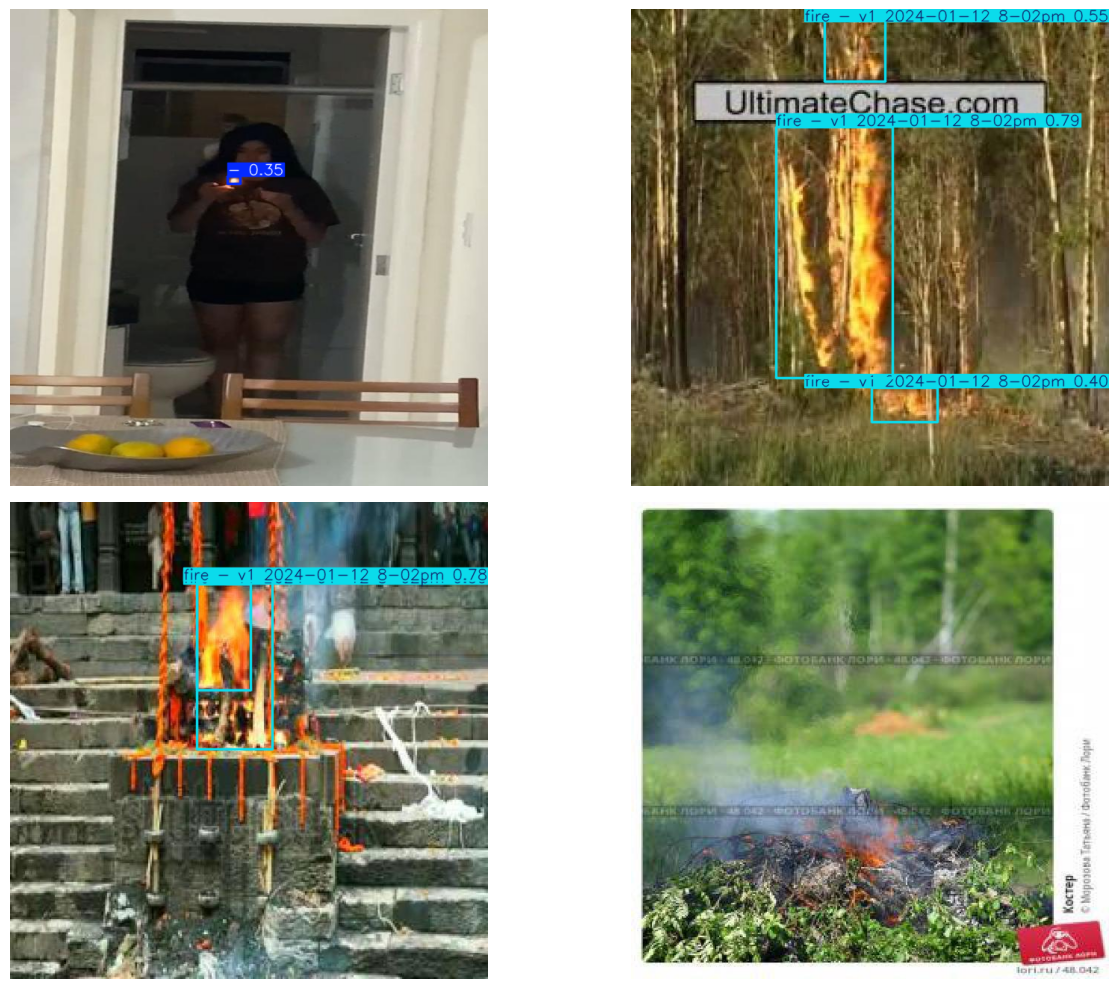

In [12]:
from ultralytics import YOLO
import glob, cv2, matplotlib.pyplot as plt

model = YOLO(f"{out}/weights/best.pt")
tests = glob.glob(f"{root}/test/images/*")[:4]
res = model.predict(tests, conf=0.25, save=True, project="/content/inferencias", name="teste", exist_ok=True)

plt.figure(figsize=(14, 10))
for i, r in enumerate(res):
    plt.subplot(2, 2, i+1)
    plt.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.tight_layout(); plt.show()

In [27]:
%%writefile uso.py
# Uso simples do modelo treinado
from ultralytics import YOLO

model = YOLO("best.pt")
results = model.predict("fogueira.jpg", conf=0.25, save=True)
for r in results:
    for box in r.boxes:
        print(model.names[int(box.cls)], float(box.conf))

Overwriting uso.py


In [28]:
import glob, shutil
img = glob.glob(f"{root}/test/images/*")[0]
shutil.copy(img, "fogueira.jpg")
print("Copiada:", img)

Copiada: /content/Fire_detector-1/test/images/WhatsApp-Video-2024-01-12-at-18_01_51_mp4-18_jpg.rf.9fc37a1c93d9c8f79cbef1d7efe1c9ba.jpg


In [29]:
!python uso.py


image 1/1 /content/fogueira.jpg: 640x640 1 -, 12.6ms
Speed: 34.4ms preprocess, 12.6ms inference, 19.9ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict-4
- 0.3495049774646759


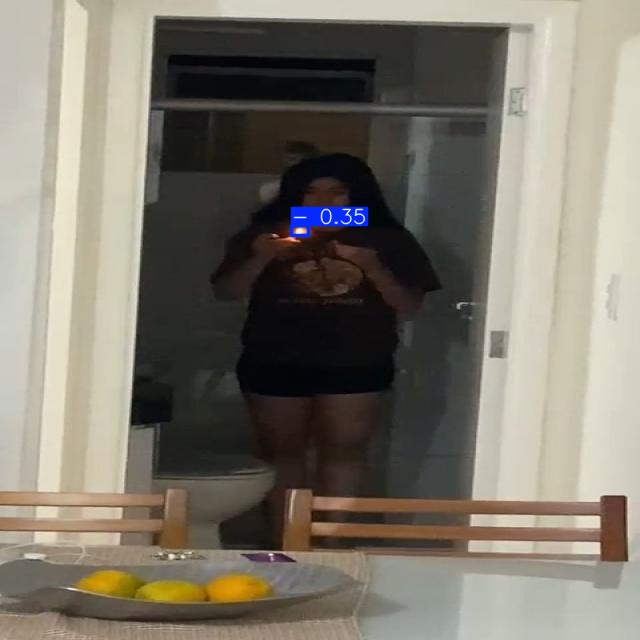

In [30]:
from IPython.display import Image, display
import glob, os
pasta = max(glob.glob("/content/runs/detect/predict*"), key=os.path.getmtime)
display(Image(glob.glob(f"{pasta}/*.jpg")[0]))

In [31]:
import glob, random, os

# a) Imagens do conjunto de teste (fogo variado)
teste = glob.glob(f"{root}/test/images/*")
random.seed(1)
amostra = random.sample(teste, 4)


minhas = ["/content/fogueira.jpg", "/content/sala_sem_fogo.jpg"]
minhas = [p for p in minhas if os.path.exists(p)]

imagens = amostra + minhas
print(len(imagens), "imagens")
for p in imagens: print(p)

5 imagens
/content/Fire_detector-1/test/images/fire1-377-_jpg.rf.3611d08e5c8f19ebf3a02dd1e05d1c43.jpg
/content/Fire_detector-1/test/images/WEBFire1863_jpg.rf.5ae10625a844b72cc5ec9241a990b1cc.jpg
/content/Fire_detector-1/test/images/89_jpg.rf.0a911a2b422e6a0334d3cc7b4725c2c7.jpg
/content/Fire_detector-1/test/images/FireDetectionImage_NoiseWEBFire1346_jpg.rf.39770755a2493380ee60763164fec40e.jpg
/content/fogueira.jpg


In [32]:
from ultralytics import YOLO
model = YOLO(f"{out}/weights/best.pt")

res = model.predict(imagens, conf=0.25, save=True,
                    project="/content/inferencias", name="teste", exist_ok=True)

for p, r in zip(imagens, res):
    print(os.path.basename(p), "->", [(model.names[int(b.cls)], round(float(b.conf), 2)) for b in r.boxes] or "nenhuma detecção")


0: 640x640 1 fire - v1 2024-01-12 8-02pm, 10.2ms
1: 640x640 3 fire - v1 2024-01-12 8-02pms, 10.2ms
2: 640x640 2 fire - v1 2024-01-12 8-02pms, 10.2ms
3: 640x640 1 fire - v1 2024-01-12 8-02pm, 10.2ms
4: 640x640 1 -, 10.2ms
Speed: 2.8ms preprocess, 10.2ms inference, 6.1ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/inferencias/teste
fire1-377-_jpg.rf.3611d08e5c8f19ebf3a02dd1e05d1c43.jpg -> [('fire - v1 2024-01-12 8-02pm', 0.71)]
WEBFire1863_jpg.rf.5ae10625a844b72cc5ec9241a990b1cc.jpg -> [('fire - v1 2024-01-12 8-02pm', 0.41), ('fire - v1 2024-01-12 8-02pm', 0.39), ('fire - v1 2024-01-12 8-02pm', 0.32)]
89_jpg.rf.0a911a2b422e6a0334d3cc7b4725c2c7.jpg -> [('fire - v1 2024-01-12 8-02pm', 0.32), ('fire - v1 2024-01-12 8-02pm', 0.27)]
FireDetectionImage_NoiseWEBFire1346_jpg.rf.39770755a2493380ee60763164fec40e.jpg -> [('fire - v1 2024-01-12 8-02pm', 0.67)]
fogueira.jpg -> [('-', 0.35)]


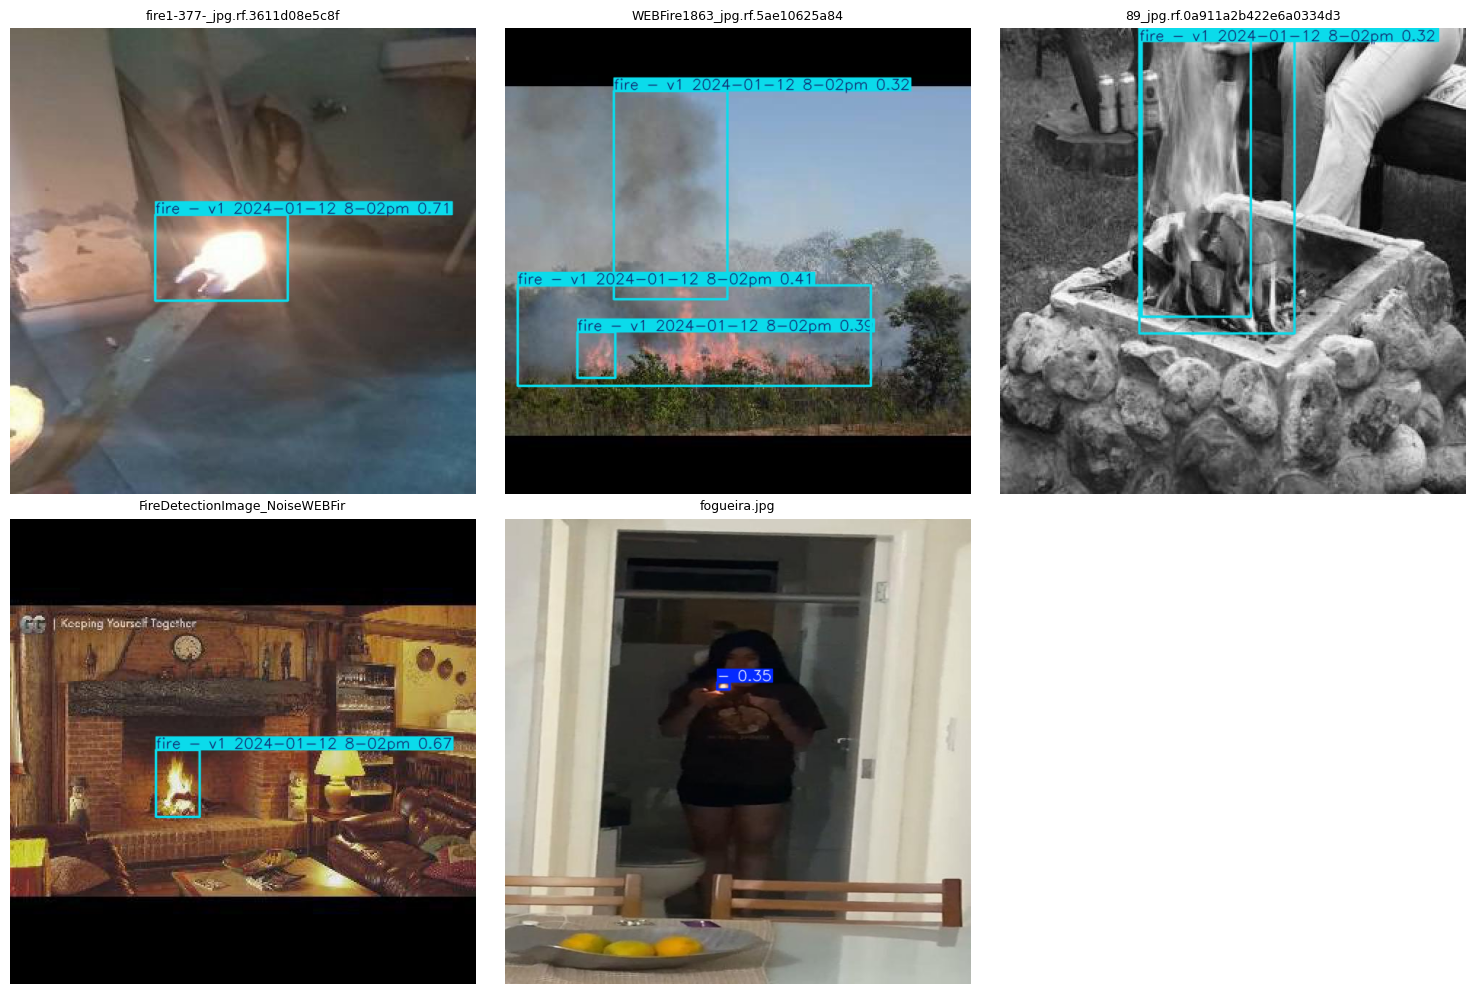

In [33]:
import cv2, math
import matplotlib.pyplot as plt

n = len(res)
cols = 3
rows = math.ceil(n / cols)
plt.figure(figsize=(15, 5 * rows))
for i, (p, r) in enumerate(zip(imagens, res)):
    plt.subplot(rows, cols, i + 1)
    plt.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB))
    plt.title(os.path.basename(p)[:30], fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.savefig("/content/inferencias/painel_inferencias.png", dpi=150)
plt.show()

In [34]:
!cd /content && zip -qr inferencias.zip inferencias
from google.colab import files
files.download("/content/inferencias.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
from google.colab import files
files.download(f"{out}/weights/best.pt")
files.download("treino.py")
files.download("uso.py")
!cd /content && zip -qr inferencias.zip inferencias
files.download("/content/inferencias.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>